# <center>IMRT: How far are we from global optimum?</center>

Clinical IMRT planning is almost always a **two-stage relaxation**: first solve fluence map optimization (FMO) for a continuous intensity per beamlet, then *sequence* that fluence into deliverable MLC segments. Stage one ignores the machine, so the plan it promises is not the plan the patient receives.

This example puts four **deliverable** methods on **one objective** and compares them with global optimal solution obtained using MIP for IMRT:

| method | what it is |
|---|---|
| **FMO + leaf sequencing + MU re-optimization** | the conventional two-stage route, done properly |
| **ColGen** | column generation: one aperture at a time |
| **ColGen + SCP** | then refine every leaf position together |
| **MIP** | machine constraints stated exactly, solved as far as time allows |

The MIP is the reference point: it is the only method that models the machine honestly, so the gap to it is what the fast methods are still leaving on the table. It is also far too slow for the clinic, which is the point.

**Every number below comes from the same function**, `linear_objective_value`. That matters more than it sounds: if each method is scored on the objective it happens to optimize, every method wins and the comparison says nothing.

In [1]:
import sys
sys.path.append('..')

### 1) Settings

The problem is deliberately small so the MIP is tractable at all: 5 beams, 10 apertures each, and a 6x down-sampling of both voxels and beamlets. Even then the MIP runs for days, so `RUN_MIP = False` and `MIP_SOLUTION` names a published solution that is downloaded and scored instead. Set `RUN_MIP = True` to solve it yourself.

`U` is the largest MU a single aperture may deliver.

In [ ]:
import os
import time

import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np

import portpy.photon as pp
from portpy.photon.imrt_scp import (create_imrt_plan, ImrtOptimizationColGen,
                                    ImrtScpOptimization)

DATA_DIR = r'../data'
PATIENT_ID = 'Lung_Patient_6'
PROTOCOL_NAME = 'Lung_2Gy_30Fx'

NUM_BEAMS = 5                  # equidistant beams
APERTURES_PER_BEAM = 10        # K: segments each beam may deliver
VOXEL_DOWN_SAMPLE = [6, 6, 1]  # x CT resolution
BEAMLET_DOWN_SAMPLE = 6        # x finest beamlet size

U = 2.0                        # max MU a single aperture may deliver
SCP_MU_MAX = 1000              # set high so the SCP's own MU cap never binds
LEAF_SEQ_LEVELS = (2, 3, 5, 10, 20, 40)   # how finely to divide the fluence (swept)

RUN_MIP = False                # True -> days. Leave False and load the published one.
MIP_SOLUTION = 'imrt_mip_Lung_Patient_6.npz'   # downloaded; '' to leave the MIP out
MIP_SOLVER = cp.GUROBI         # see section 7 for why not MOSEK
MIP_PARAMS = dict(TimeLimit=360000, Cuts=2, Symmetry=2, MIPFocus=1, Heuristics=0.2)

aperture_budget = NUM_BEAMS * APERTURES_PER_BEAM
results = []                   # one (name, dose, seconds, segments) row per method
print(f'{NUM_BEAMS} beams x {APERTURES_PER_BEAM} apertures = {aperture_budget} segment budget')

### 2) Load the patient and down-sample

The influence matrix `A` maps beamlet intensities to voxel doses, so `dose = A @ x`. Down-sampling shrinks both of its dimensions; without it the MIP would have no chance.

In [3]:
data = pp.DataExplorer(data_dir=DATA_DIR)
data.patient_id = PATIENT_ID

ct = pp.CT(data)
structs = pp.Structures(data)

# pick NUM_BEAMS equidistant beams out of everything the patient has
all_beam_ids = data.load_metadata()['beams']['ID']
beam_ids = list(all_beam_ids[::max(1, len(all_beam_ids) // NUM_BEAMS)])[:NUM_BEAMS]
beams = pp.Beams(data, beam_ids=beam_ids)

clinical_criteria = pp.ClinicalCriteria(data, protocol_name=PROTOCOL_NAME)
opt_params = data.load_config_opt_params(protocol_name=PROTOCOL_NAME)
structs.create_opt_structures(opt_params=opt_params, clinical_criteria=clinical_criteria)

inf_matrix = pp.InfluenceMatrix(ct=ct, structs=structs, beams=beams)
inf_matrix_db = inf_matrix.create_down_sample(
    beamlet_width_mm=beams.get_finest_beamlet_width() * BEAMLET_DOWN_SAMPLE,
    beamlet_height_mm=beams.get_finest_beamlet_height() * BEAMLET_DOWN_SAMPLE,
    opt_vox_xyz_res_mm=[r * f for r, f in zip(ct.get_ct_res_xyz_mm(), VOXEL_DOWN_SAMPLE)])

my_plan = pp.Plan(ct=ct, structs=structs, beams=beams, inf_matrix=inf_matrix_db,
                  clinical_criteria=clinical_criteria)
A = inf_matrix_db.A
print(f'beams {beam_ids}\ndown-sampled A: {A.shape[0]} voxels x {A.shape[1]} beamlets')

Creating optimization structures.. It may take some time due to dilation


Optimization structures created!!


Creating BEV..


Loading sparse influence matrix...
Done


reindexing voxels...


...

parsing influence matrix for beam 1


parsing influence matrix for beam 2


parsing influence matrix for beam 3


parsing influence matrix for beam 4


creating influence matrix for down sample voxels..
beams [0, 14, 28, 42, 56]
down-sampled A: 83320 voxels x 106 beamlets


### 3) One objective for every method

The clinical protocol states its dose objectives as **quadratic**. Quadratic objectives combined with the MIP's yes/no variables are much harder to solve, so this example uses the **linear** counterpart throughout: for each structure, `weight / n_voxels * sum(slack)`, where the slack is how far a voxel sits past its dose goal.

Two functions below, and they must agree:

* `linear_objectives` adds that objective to a CVXPY problem (used by FMO and the MIP);
* `linear_objective_value` evaluates the identical expression on any dose vector. At the optimum the slacks take their natural values, `max(0, d - goal)` and `max(0, goal - d)`, so no optimizer is needed to score a plan.

ColGen and the SCP are put on the same objective in section 6.

In [4]:
def linear_objectives(opt, opt_params, my_plan, inf_matrix, clinical_criteria):
    """Add the linear dose objectives to a CVXPY problem."""
    x = opt.vars['x']
    A = inf_matrix.A
    opt.obj = []
    for obj in opt_params.get('objective_functions', []):
        struct = obj.get('structure_name')
        if struct not in my_plan.structures.get_structures():
            continue
        idx = inf_matrix.get_opt_voxels_idx(struct)
        if len(idx) == 0:
            continue
        w = obj['weight']
        if obj['type'] == 'quadratic-overdose':
            gy = opt.get_num(obj['dose_gy']) / clinical_criteria.get_num_of_fractions()
            dO = cp.Variable(len(idx), pos=True)
            opt.obj += [(1 / len(idx)) * (w * cp.sum(dO))]
            opt.constraints += [A[idx, :] @ x <= gy + dO]
        elif obj['type'] == 'quadratic-underdose':
            gy = opt.get_num(obj['dose_gy']) / clinical_criteria.get_num_of_fractions()
            dU = cp.Variable(len(idx), pos=True)
            opt.obj += [(1 / len(idx)) * (w * cp.sum(dU))]
            opt.constraints += [A[idx, :] @ x >= gy - dU]
        elif obj['type'] == 'quadratic':
            opt.obj += [(1 / len(idx)) * (w * cp.sum(A[idx, :] @ x))]


def linear_objective_value(dose_1d, opt_params, my_plan, inf_matrix,
                           clinical_criteria, get_num):
    """Score ANY plan with the objective linear_objectives minimizes.

    dose_1d is dose PER FRACTION on the optimization voxels.
    """
    total = 0.0
    nf = clinical_criteria.get_num_of_fractions()
    for obj in opt_params.get('objective_functions', []):
        struct = obj.get('structure_name')
        if struct not in my_plan.structures.get_structures():
            continue
        idx = inf_matrix.get_opt_voxels_idx(struct)
        if len(idx) == 0:
            continue
        d = dose_1d[idx]
        w = obj['weight']
        if obj['type'] == 'quadratic-overdose':
            gy = get_num(obj['dose_gy']) / nf
            total += w / len(idx) * float(np.sum(np.maximum(0.0, d - gy)))
        elif obj['type'] == 'quadratic-underdose':
            gy = get_num(obj['dose_gy']) / nf
            total += w / len(idx) * float(np.sum(np.maximum(0.0, gy - d)))
        elif obj['type'] == 'quadratic':
            total += w / len(idx) * float(np.sum(d))
    return total


results = []   # (name, dose_1d, seconds, segment_count)

### 4) The fluence map (FMO)

Optimize the beamlet intensities with no machine constraints. This is **not a treatment plan** -- no MLC can produce this fluence exactly -- so it is not one of the four methods. It is the input to leaf sequencing in the next section.

The protocol's **smoothness** term is added back here. It is left out of the objective every method is scored on (the MIP does not model it), but it belongs in this solve: leaf sequencing has to follow this fluence, and a spiky one needs many stratification levels, which costs both accuracy and segments.

In [5]:
smooth_weight = next((o['weight'] for o in opt_params['objective_functions']
                      if o['type'] == 'smoothness-quadratic'), 0.0)

opt_fmo = pp.Optimization(my_plan, opt_params=opt_params)
opt_fmo.create_cvxpy_problem()
linear_objectives(opt_fmo, opt_params, my_plan, inf_matrix_db, clinical_criteria)

# smoothness: penalize neighbouring beamlets that differ, so the fluence is one an MLC can follow
Qx, Qy, sm_rows, sm_cols = pp.Optimization.get_smoothness_matrix(inf_matrix_db.beamlets_dict)
opt_fmo.obj += [smooth_weight * (0.6 * (1 / sm_cols) * cp.sum_squares(Qx @ opt_fmo.vars['x'])
                                 + 0.4 * (1 / sm_rows) * cp.sum_squares(Qy @ opt_fmo.vars['x']))]

t0 = time.time()
sol_fmo = opt_fmo.solve(solver=cp.MOSEK, verbose=False)
t_fmo = time.time() - t0
print(f'FMO: {t_fmo:.1f} s, smoothness weight {smooth_weight}')

Problem created
Running Optimization..


Optimal value: 1369.6723173497353
Elapsed time: 0.7911674976348877 seconds
FMO: 0.8 s, smoothness weight 100


### 5) Method 1 - FMO + leaf sequencing + MU re-optimization

Leaf sequencing turns the fluence map into a set of MLC segments the machine can deliver.

How many segments you get is **not** something you set directly - it follows from how finely the fluence is divided up. Finer means a closer match to the fluence, but more segments and a longer treatment. A single arbitrary setting would either flatter or cripple this method, so we try a range and read off the row whose segment count is closest to the budget the other methods are held to.

`A @ seq['optimal_intensity']` is the dose the patient would actually receive, not the fluence the optimizer asked for.

In [6]:
best = None
print('levels   segments   objective')
for levels in LEAF_SEQ_LEVELS:
    t0 = time.time()
    seq = pp.leaf_sequencing_siochi(my_plan, sol_fmo, num_of_levels=levels)
    t_seq = time.time() - t0
    n_seg = sum(len(v['MU']) for k, v in seq.items() if isinstance(v, dict))
    dose = np.asarray(A @ seq['optimal_intensity'])
    obj = linear_objective_value(dose, opt_params, my_plan, inf_matrix_db,
                                 clinical_criteria, opt_fmo.get_num)
    print(f'{levels:6d} {n_seg:10d} {obj:11.3f}')
    # keep whichever level lands closest to the segment budget
    if best is None or abs(n_seg - aperture_budget) < abs(best[1] - aperture_budget):
        best = (levels, n_seg, t_fmo + t_seq, seq)

best_levels, best_seg, best_time, best_seq = best
print(f'\nmatched to the {aperture_budget}-segment budget -> levels={best_levels}, '
      f'{best_seg} segments')

levels   segments   objective
     2         14    9670.711
     3         20    6876.981
     5         31    3968.878
    10         48    2403.090
    20         63    1415.111
    40         79    1411.790

matched to the 50-segment budget -> levels=10, 48 segments


Stratification rounds the fluence, so the MU of every segment is slightly wrong. The fix is standard practice and cheap: **keep the aperture shapes and re-solve only their MUs**.

`Z` records which beamlets each segment leaves open, and `x == Z.T @ mu` ties the fluence to a sum of those segments - which is what keeps the result deliverable. Building it as a `pp.Optimization` matters: it inherits the same objective *and* the same clinical constraints as every other method. A plain LP over `mu` without those constraints scored below the FMO - impossible for a deliverable plan, and the tell that constraints had gone missing.

In [7]:
t0 = time.time()
cols = []
for beam_id in my_plan.beams.get_all_beam_ids():
    gantry_angle = my_plan.beams.get_gantry_angle(beam_id=beam_id)
    if gantry_angle not in best_seq:
        continue
    grid = inf_matrix_db.get_bev_2d_grid(beam_id=beam_id, finest_grid=False)
    for shape in best_seq[gantry_angle]['leaf_shapes']:
        idx = grid[np.asarray(shape) > 0]
        col = np.zeros(A.shape[1])
        col[idx[idx >= 0]] = 1.0
        cols.append(col)
Z = np.asarray(cols)              # (segments, beamlets), 1 = beamlet open in that segment

opt_re = pp.Optimization(my_plan, opt_params=opt_params)
opt_re.create_cvxpy_problem()
linear_objectives(opt_re, opt_params, my_plan, inf_matrix_db, clinical_criteria)
mu_re = cp.Variable(Z.shape[0], nonneg=True)
opt_re.constraints += [opt_re.vars['x'] == Z.T @ mu_re]
opt_re.solve(solver=cp.MOSEK, verbose=False)

w_re = np.maximum(np.asarray(mu_re.value).ravel(), 0.0)
dose_re = np.asarray(A @ (Z.T @ w_re))
n_seg_re = int(np.sum(w_re > 1e-9))
t_re = time.time() - t0
results.append(('FMO + leaf seq', dose_re, best_time + t_re, n_seg_re))
print(f'MU re-optimization: {best_seg} segments -> {n_seg_re} with MU, '
      f'total MU {w_re.sum():.2f}, {t_re:.1f} s, objective '
      f'{linear_objective_value(dose_re, opt_params, my_plan, inf_matrix_db, clinical_criteria, opt_fmo.get_num):.3f}')

Problem created
Running Optimization..


Optimal value: 1415.5788535383797
Elapsed time: 0.6954531669616699 seconds
MU re-optimization: 48 segments -> 46 with MU, total MU 7.95, 0.7 s, objective 1415.579


### 6) Methods 2 and 3 - ColGen and ColGen + SCP (direct aperture optimization)

Rather than optimizing a fluence and hoping it sequences well, these optimize **aperture shapes and their MUs directly**, so every iterate is deliverable.

* `create_imrt_plan` gives each of the K apertures its own block of influence-matrix columns. This is what lets one beam deliver several different shapes.
* **Column generation** builds the plan greedily, pricing one aperture at a time against the dose still missing. Reported on its own, as method 2.
* **SCP** (sequential convex programming) then refines the leaf positions of all apertures together, repeatedly solving a convex approximation. Method 3.

The VMAT protocol's objectives are swapped for their linear counterparts so these optimize exactly what the MIP does. The aperture regularity/similarity terms are dropped, since the MIP does not model them - leaving them in would mean the methods are again minimizing different things.

In [8]:
LINEARISE = {'quadratic-overdose': 'linear-overdose',
             'quadratic-underdose': 'linear-underdose',
             'quadratic': 'linear'}

vmat_params = data.load_config_opt_params(protocol_name=f'{PROTOCOL_NAME}_vmat')
vmat_params['opt_parameters']['initial_leaf_pos'] = 'CG'
vmat_params['opt_parameters']['mu_max'] = SCP_MU_MAX
vmat_params['objective_functions'] = [
    dict(obj, type=LINEARISE[obj['type']])
    for obj in vmat_params['objective_functions'] if obj['type'] in LINEARISE]

imrt_plan = create_imrt_plan(my_plan, num_apertures=APERTURES_PER_BEAM)


def segments_with_mu(sol):
    """How many apertures actually get MU (a shape with zero MU is not delivered)."""
    mu = np.asarray(sol['optimal_intensity'])
    return int(np.sum([np.any(mu[b['start_beamlet_idx']:b['end_beamlet_idx'] + 1] > 1e-9)
                       for b in imrt_plan.inf_matrix.beamlets_dict]))


t0 = time.time()
cg_opt = ImrtOptimizationColGen(my_plan=imrt_plan, opt_params=vmat_params)
sol_cg = cg_opt.run_col_gen_algo(solver='MOSEK', verbose=False, accept_unknown=True)
t_cg = time.time() - t0
dose_cg = np.asarray(imrt_plan.inf_matrix.A @ sol_cg['optimal_intensity'])
results.append(('ColGen', dose_cg, t_cg, segments_with_mu(sol_cg)))
print(f'ColGen: {t_cg:.1f} s, objective '
      f'{linear_objective_value(dose_cg, opt_params, my_plan, inf_matrix_db, clinical_criteria, opt_fmo.get_num):.3f}')

scp_opt = ImrtScpOptimization(my_plan=imrt_plan, opt_params=vmat_params)
convergence = scp_opt.run_sequential_cvx_algo(solver='MOSEK', verbose=False)
t_scp = time.time() - t0
sol_scp = convergence[scp_opt.best_iteration]
dose_scp = np.asarray(sol_scp.get('best_act_dose_v', sol_scp['act_dose_v']))
results.append(('ColGen + SCP', dose_scp, t_scp, segments_with_mu(sol_scp)))
print(f'ColGen + SCP: {t_scp:.1f} s, {len(convergence)} SCP iterations, objective '
      f'{linear_objective_value(dose_scp, opt_params, my_plan, inf_matrix_db, clinical_criteria, opt_fmo.get_num):.3f}')

ColGen: 75.1 s, objective 1698.638
ColGen + SCP: 177.2 s, 10 SCP iterations, objective 1379.439


### 7) Method 4 - the deliverability-constrained MIP

Here the machine is modelled exactly, with one yes/no variable per beamlet per aperture:

* `z[a, b]` - is beamlet `b` open in aperture `a`?
* `mu[a] <= U` - that aperture's monitor units.
* `y[a, b]` - the MU beamlet `b` actually receives: `mu[a]` if it is open, `0` if it is shut. Writing that directly as `mu[a] * z[a, b]` would multiply two unknowns together, which the solver cannot take, so it is rewritten as the three inequalities in the code.
* A leaf pair leaves **one continuous opening**, not an arbitrary scatter of beamlets. That is what `sum(z) == rbi - lbi - 1` enforces, with `lbi` and `rbi` the two leaf positions.
* The beam's fluence is the **sum** over its apertures.
* `mu[a] >= mu[a+1]` stops the solver re-exploring the same plan with its apertures relabelled.

**Why Gurobi and not MOSEK here.** Gurobi can throw away branches that cannot beat a value you hand it; MOSEK's equivalent setting only stops once its own bound passes that value. On this problem MOSEK reached 1975.67 (32% gap) in 102 hours, where Gurobi reached 1370.96 (2.1% gap) in 90.

Expect days, and expect the **gap to close only from above**. The simplified version of the problem that the solver uses to bound its search is weak here - it works out to exactly the FMO value - so the lower bound barely moves and optimality is never proven in practice.

In [ ]:
def build_beam_maps(inf_matrix, beam_ids):
    """Per beam: the beam's-eye-view grid and the beamlets in each leaf row."""
    beams_info = []
    for beam_map in inf_matrix.get_bev_2d_grid(beam_id=beam_ids):
        beam_map = beam_map[~np.all(beam_map == -1, axis=1), :]   # drop empty rows
        num_rows, num_cols = beam_map.shape
        beams_info.append({'beam_map': beam_map, 'num_rows': num_rows, 'num_cols': num_cols,
                           'row_beamlets': {r: row[row >= 0].tolist()
                                            for r, row in enumerate(beam_map)}})
    return beams_info


if RUN_MIP:
    opt_mip = pp.Optimization(my_plan, opt_params=opt_params)
    opt_mip.create_cvxpy_problem()
    linear_objectives(opt_mip, opt_params, my_plan, inf_matrix_db, clinical_criteria)

    beams_info = build_beam_maps(inf_matrix_db, my_plan.beams.get_all_beam_ids())
    n_beamlets = A.shape[1]
    x = opt_mip.vars['x']
    n_ap_total = len(beams_info) * APERTURES_PER_BEAM
    total_rows = sum(b['num_rows'] for b in beams_info) * APERTURES_PER_BEAM

    z = cp.Variable((n_ap_total, n_beamlets), boolean=True)
    y = cp.Variable((n_ap_total, n_beamlets), nonneg=True)
    mu = cp.Variable(n_ap_total, nonneg=True)
    lbi = cp.Variable(total_rows, integer=True)
    rbi = cp.Variable(total_rows, integer=True)

    row_offset = 0
    for i, beam in enumerate(beams_info):
        beam_beamlets = sorted({b for bl in beam['row_beamlets'].values() for b in bl})
        for k in range(APERTURES_PER_BEAM):
            a = i * APERTURES_PER_BEAM + k
            for leaf, beamlets in beam['row_beamlets'].items():
                if not beamlets:
                    continue
                r = row_offset + leaf
                c = np.where(np.isin(beam['beam_map'], beamlets))   # column positions
                opt_mip.constraints += [
                    # one contiguous open run between the two leaves
                    rbi[r] - cp.multiply(c[1] + 1, z[a, beamlets]) >= 1,
                    cp.multiply(beam['num_cols'] - c[1], z[a, beamlets]) + lbi[r] <= beam['num_cols'],
                    cp.sum(z[a, beamlets]) == rbi[r] - lbi[r] - 1,
                    rbi[r] <= beam['num_cols'] + 1,
                    # y = mu * z, linearized
                    y[a, beamlets] <= U * z[a, beamlets],
                    y[a, beamlets] <= mu[a],
                    y[a, beamlets] >= mu[a] - U * (1 - z[a, beamlets]),
                ]
            closed = [b for b in range(n_beamlets) if b not in beam_beamlets]
            if closed:
                opt_mip.constraints += [z[a, closed] == 0, y[a, closed] == 0]
            opt_mip.constraints += [mu[a] <= U]
            row_offset += beam['num_rows']
        # the beam's fluence is the SUM over its apertures
        aps = [i * APERTURES_PER_BEAM + k for k in range(APERTURES_PER_BEAM)]
        opt_mip.constraints += [x[beam_beamlets] == cp.sum(y[aps, :], axis=0)[beam_beamlets]]
        # symmetry breaking: order the MUs
        opt_mip.constraints += [mu[aps[k]] >= mu[aps[k + 1]]
                                for k in range(APERTURES_PER_BEAM - 1)]
    opt_mip.constraints += [lbi >= 0, rbi >= 0]

    print(f'MIP: {len(beams_info)} beams x {APERTURES_PER_BEAM} apertures, '
          f'{n_ap_total * n_beamlets} binaries -- this will take hours')
    t0 = time.time()
    sol_mip = opt_mip.solve(solver=MIP_SOLVER, verbose=True, **MIP_PARAMS)
    t_mip = time.time() - t0

    dose_mip = np.asarray(A @ sol_mip['optimal_intensity'])
    results.append(('MIP', dose_mip, t_mip, int(np.sum(mu.value > 1e-9))))
    print(f'MIP: {t_mip:.1f} s')
elif MIP_SOLUTION:
    # score a MIP solved earlier instead of re-solving it. It is the best plan FOUND in
    # the time it was given, not a proven optimum. A bare name is downloaded and cached.
    sol_path = (MIP_SOLUTION if os.path.exists(MIP_SOLUTION)
                else str(pp.download_artifact(MIP_SOLUTION)))
    if sol_path.endswith('.npz'):
        with np.load(sol_path) as npz:
            sol_mip = {k: npz[k] for k in npz.files if not k.startswith('meta_')}
    else:
        sol_mip = pp.load_optimal_sol(sol_name=os.path.basename(sol_path),
                                      path=os.path.dirname(sol_path))
    intensity = np.asarray(sol_mip['optimal_intensity']).ravel()
    if intensity.size != A.shape[1]:
        raise ValueError(f'{os.path.basename(sol_path)} holds {intensity.size} beamlet '
                         f'intensities but this plan has {A.shape[1]}. A saved solution only '
                         f'applies to the geometry it was solved for: re-solve with '
                         f'RUN_MIP = True, or restore the settings it was made for.')
    dose_mip = np.asarray(A @ intensity)
    results.append(('MIP', dose_mip, float('nan'),
                    int(np.sum(np.asarray(sol_mip['MU']) > 1e-9))))
    print(f'MIP loaded from {sol_path}')
else:
    print('No MIP: set RUN_MIP = True to solve one, or point MIP_SOLUTION at a '
          'solution you have already saved.')

### 8) Compare

One objective, one table. `gap %` is measured against the **MIP**, the best deliverable plan we can produce.

Segment counts are reported alongside, because a method that buys quality with twice the segments has not won outright: more segments means a longer treatment.

In [10]:
objectives = [linear_objective_value(dose, opt_params, my_plan, inf_matrix_db,
                                     clinical_criteria, opt_fmo.get_num)
              for _, dose, _, _ in results]
ref_i = next((i for i, (n, _, _, _) in enumerate(results) if n.startswith('MIP')), None)
ref_obj = objectives[ref_i] if ref_i is not None else min(objectives)

ptv = inf_matrix_db.get_opt_voxels_idx('PTV')
nf = clinical_criteria.get_num_of_fractions()

print(f'{"method":<26}{"objective":>11}{"gap %":>8}{"segs":>7}{"time s":>9}'
      f'{"D95":>9}{"mean":>9}{"Dmax":>9}')
for (name, dose, secs, segs), obj in zip(results, objectives):
    d = dose[ptv] * nf
    print(f'{name:<26}{obj:11.3f}{100 * (obj - ref_obj) / ref_obj:8.2f}{segs:7d}'
          f'{"-" if secs != secs else f"{secs:.1f}":>9}'
          f'{np.percentile(d, 5):9.2f}{d.mean():9.2f}{d.max():9.2f}')

method                      objective   gap %   segs   time s      D95     mean     Dmax
FMO + leaf seq               1415.579    3.25     46      1.6    58.95    62.08    66.00
ColGen                       1698.638   23.90     39     75.1    58.11    62.07    66.00
ColGen + SCP                 1379.439    0.62     50    177.2    59.07    62.13    66.00
MIP                          1370.956    0.00     50        -    58.99    62.10    66.00


One bar per method, with the segments and time it needed. The dashed line is the MIP, and the number inside each bar is its gap to it.

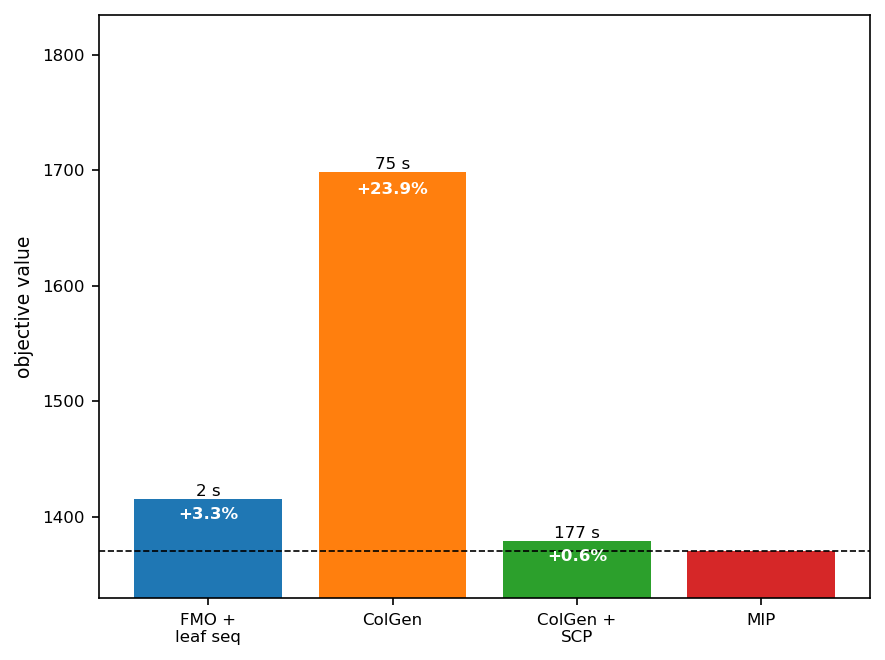

In [11]:
fig, ax = plt.subplots(figsize=(6, 4.5), dpi=150)
labels = [n.replace(' + ', ' +\n') for n, _, _, _ in results]
bars = ax.bar(labels, objectives, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])

for i, (bar, (_, _, secs, segs)) in enumerate(zip(bars, results)):
    if secs == secs:                       # no time for a loaded solution
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                f'{round(secs)} s', ha='center', va='bottom', fontsize=8)
    if i != ref_i:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 0.995,
                f'{100 * (objectives[i] - ref_obj) / ref_obj:+.1f}%',
                ha='center', va='top', fontsize=8, color='white', fontweight='bold')

ax.axhline(ref_obj, ls='--', color='black', lw=0.8)
ax.set_ylabel('objective value', fontsize=9)
ax.set_ylim(min(objectives) * 0.97, max(objectives) * 1.08)
ax.tick_params(labelsize=8)
plt.tight_layout()
plt.savefig('imrt_objective_comparison.png', dpi=300)
plt.show()

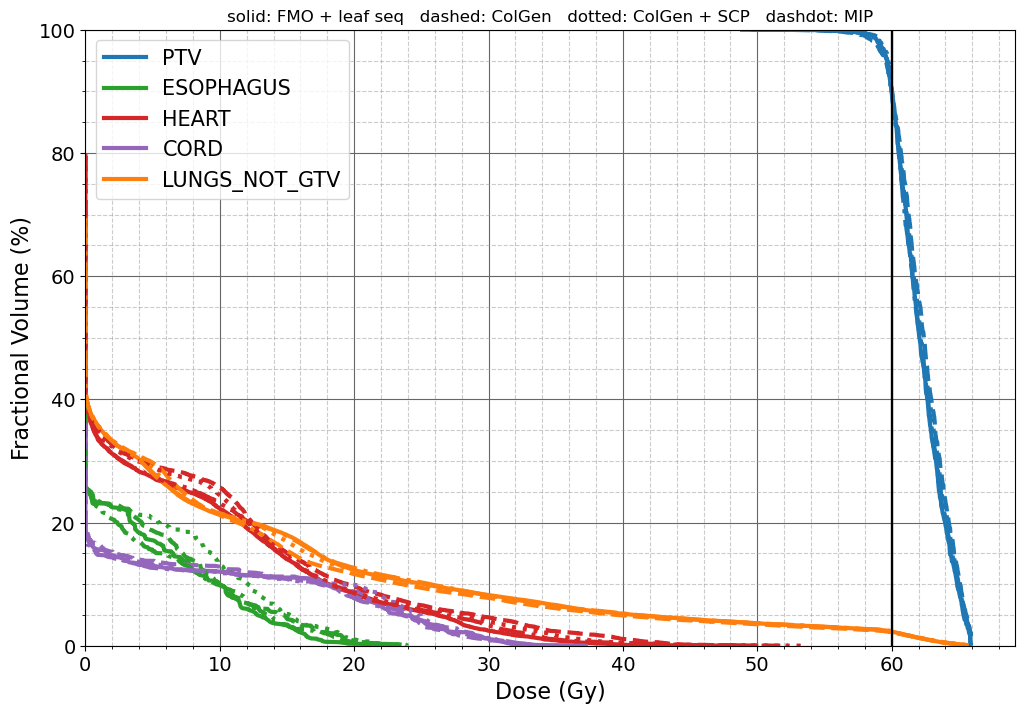

In [12]:
STRUCTS_TO_PLOT = ['PTV', 'ESOPHAGUS', 'HEART', 'CORD', 'LUNGS_NOT_GTV']
STYLES = ['solid', 'dashed', 'dotted', 'dashdot']

fig, ax = plt.subplots(figsize=(12, 8))
for (name, dose, _, _), style in zip(results, STYLES):
    ax = pp.Visualization.plot_dvh(my_plan, dose_1d=dose * nf, struct_names=STRUCTS_TO_PLOT,
                                   style=style, ax=ax, norm_flag=True)
ax.set_title('   '.join(f'{s}: {n}' for (n, _, _, _), s in zip(results, STYLES)))
plt.savefig('imrt_dvh_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

#### Plan score

The objective says which method optimized best. It does not say whether that difference matters clinically. The scorecard does: it awards points per dose-volume criterion the way a planner does when accepting or rejecting a plan, and `Evaluation.get_plan_score` sums them.

Each criterion's points are a piecewise-linear interpolation of the scorecard's tolerance bands at the achieved value, so a plan loses points gradually as it drifts from the ideal rather than passing or failing a threshold. Criteria for structures this patient does not have are skipped, which is why the maximum attainable total is patient specific.

Scores below are computed on the same down-sampled optimization voxels the methods were optimized on, so they line up with the objective column above.

In [13]:
import json

# The scorecard ships with PortPy. This one is 2Gy x 30Fx = 60Gy, the same prescription
# used here. For a scorecard written for a different prescription, rescale it first with
# portpy.photon.utils.adapt_scorecard_prescription.
scorecard_path = os.path.join(os.path.dirname(os.path.dirname(pp.__file__)),
                              'config_files', 'scorecard',
                              'SC_Lung(60Gy)_2022MAAS_ExampleV2.json')
with open(scorecard_path, 'r') as f:
    scorecard_json = json.load(f)

# map scorecard structure names onto the names used in the PortPy plan
alias_map = {'SPINAL_CORD': 'CORD', 'TOTAL LUNG - GTV': 'LUNGS_NOT_GTV'}

print(f'{"method":<26}{"plan score":>12}')
for name, dose, _, _ in results:
    score, score_df = pp.Evaluation.get_plan_score(
        plan=my_plan, dose_1d=dose * nf, scorecard_json=scorecard_json,
        prescription_gy=my_plan.get_prescription(), alias_map=alias_map,
        return_score_df=True)
    print(f'{name:<26}{score:12.2f}')

# criterion by criterion for the last method scored, so a total can always be traced back
# to the criteria that produced it. 'missing_structure' rows are skipped, not scored zero,
# so the maximum attainable total is patient specific.
print()
print(score_df[['Structure', 'MetricType', 'MetricValue', 'Score', 'Status']].to_string(index=False))

method                      plan score
FMO + leaf seq                   73.11
ColGen                           72.94
ColGen + SCP                     73.27
MIP                              73.23

       Structure   MetricType  MetricValue     Score            Status
             PTV VolumeAtDose    92.401154  0.000000                ok
             CTV VolumeAtDose          NaN       NaN missing_structure
             PTV VolumeAtDose    99.663482  9.831741                ok
             PTV VolumeAtDose    99.978156  3.912623                ok
             PTV DoseAtVolume    66.006843  0.000000                ok
             PTV DoseAtVolume    57.994924  8.000000                ok
TOTAL LUNG - GTV VolumeAtDose    12.668373 14.000000                ok
TOTAL LUNG - GTV VolumeAtDose    27.995057  5.000000                ok
TOTAL LUNG - GTV     MeanDose     7.080282  8.000000                ok
     SPINAL_CORD DoseAtVolume    34.028339  4.487629                ok
           HEART DoseAt

### 9) What to take away

Measured on this problem (Lung_Patient_6, 5 beams, 50-segment budget, linear objective):

| method |  objective | gap to MIP | time |
|---|-----------:|-----:|------:|
| FMO + leaf seq (+ MU re-optimization) |     1415.6 | +3.3% | 2 s |
| ColGen |     1698.6 | +23.9% | 74 s |
| ColGen + SCP |     1379.4 | +0.6% | 173 s |
| **MIP** | **1370.9** |  - | ~90 h |

**The two-stage route is better than its reputation - if you re-optimize the MUs.** At 46 segments it lands 3.3% above the MIP in two seconds. Without the MU step the same apertures score 2403 (section 5's sweep at `L=10`); raw sequencing needs 63 segments to reach the same quality the MU step gets from 46. Its weakness is *segment efficiency*, not an inability to produce good plans.

**Column generation alone is not enough.** It is greedy: each aperture is chosen against the dose still missing and never revisited, so it stops 23.9% above the MIP. The SCP, which moves every leaf together, is what closes that gap. Its 39 segments are real - ColGen builds all 50 apertures, but the restricted master gives 11 of them no MU, and an aperture with no MU is not delivered.

**The fast method is almost at the reference.** ColGen + SCP lands 0.6% above the MIP in three minutes, against 90 hours - and the MIP never proved optimality, because the relaxation it bounds with works out to the FMO value and barely moves. So the gap a user gives up by taking the fast route is smaller than the uncertainty left in the MIP itself.


**Ideas to extend this:** sweep `APERTURES_PER_BEAM` to trade plan quality against delivery time; or hand the MIP a known deliverable plan as a starting value so it can discard branches sooner.